## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [3]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Armon Haji

**Date:** 10/21/2026

In [12]:
# Your Phase 1 solution to the problem goes here.

# Q1

import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

In [13]:
token_freq[:10]

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927),
 ('like', 923),
 ('2002', 869),
 ('would', 806),
 ('one', 798),
 ('message', 795)]

In [14]:
import matplotlib.pyplot as plt

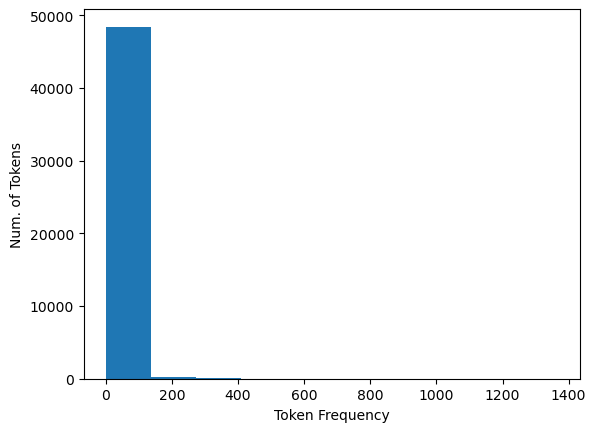

In [15]:
counts = []

for x in token_freq:
    counts.append(x[1])

plt.hist(counts)
plt.xlabel("Token Frequency")
plt.ylabel("Num. of Tokens")
plt.show()

In [16]:
## We can see clearly here that most of the tokens appear only a small number of times, while a few tokens appear very frequently. The 
## histogram is very right-skewed. This is due to the fact that there are a small number of words with very high frequencies.

In [17]:
# Q2

import pandas as pd

df = pd.read_parquet("data/Phishing_clean.parquet")
df.head()

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training R2:", model.score(X_train, y_train))
print("Testing R2:", model.score(X_test, y_test))

coef = pd.Series(model.coef_, index=X.columns)
print(coef.abs().sort_values(ascending=False).head(10))

Training R2: 0.7670143724934355
Testing R2: 0.6658718438847929
intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
gray;                0.574480
dtype: float64


In [19]:
## It appears the training R2 was about 0.77 and the testing R2 was about 0.67. What this means is 
## that the model did better on training data than testing data.  Words with bigger coefficients had 
## the strongest effect on the model's predictions.

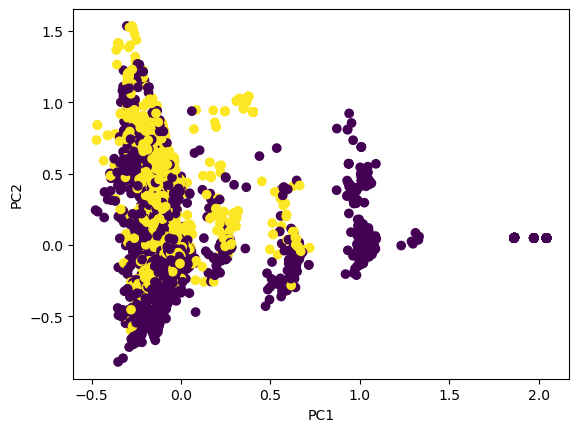

In [20]:
# Q3

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:,0], X_pca[:,1], c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [21]:
## There is separation between phishing and non-phishing emails. However, there's still a lot of 
## overlap. What this means is that the first two principal components capture some differences, 
## but they do not completely separate them.

In [22]:
# Q4

from sklearn.decomposition import PCA

pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model2 = LinearRegression()
model2.fit(X_train_pca, y_train)

print("Training R2:", model2.score(X_train_pca, y_train))
print("Testing R2:", model2.score(X_test_pca, y_test))

Training R2: 0.7662326827745852
Testing R2: 0.6683390643101161


In [23]:
## The PCA model had about the same performance as the original regression. The training R2 was about
## 0.77 and the testing R2 was about 0.67. This means that the testing result was slightly better 
## with PCA.

In [24]:
# Q5

## PCA is useful because it takes a large number of variables and combines them into fewer 
## components. It even does this while still keeping most of the important information. This can 
## make the regression easier to work with and can also reduce problems from variables that are very 
## similar to each other.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 787a21c8424783867ee7b84da74796804dde87cf
- **AI tool and model used:** Chat GPT

### *Prompts used

1. Improve assignment in any way you can. Find gaps of effiency, wrong things, etc.
   
2. Improve my token frequency histogram and make the distribution easier to interpret.

3. Improve my linear regression analysis and make the important coefficients easier to understand.

4. Improve my PCA analysis and make the two-component scatterplot easier to interpret.

5. Improve my PCA regression analysis and make the comparison to the original regression clearer.

6. Improve my explanation of why PCA can be useful in a high-dimensional regression and mention any important limitations.

### *AI-proposed changes


1. Q1: Use a log scale for the token-frequency histogram so the long right tail is easier to see, and add a clearer title/labels.

2. Q2: Keep the same regression but present the largest coefficients more clearly and explain that large absolute coefficients have the strongest influence on predictions.

3. Q3: Improve the PCA scatterplot by adding a legend for phishing vs. non-phishing and include the explained variance from the first two principal components.

4. Q4: Show the PCA regression and original regression results together so the training and testing R2 values are easier to compare.

5. Q5: Expand the PCA explanation to mention that PCA reduces dimensionality and redundancy, but the new components can be harder to interpret than the original variables.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The histogram is very right-skewed, so using a log scale should make the smaller frequencies easier to see. I can verify this by comparing the new graph to the original one. |
| 2 | Accept | The regression already works, but the important coefficients could be shown more clearly. I can verify this by checking that the same top words still appear. |
| 3 | Accept | A legend will make the PCA plot easier to understand, and explained variance gives more information about how much the first two components capture. |
| 4 | Accept | Putting both regression results together makes the comparison easier. I can verify the values using the R2 scores from Q2 and Q4. |
| 5 | Accept | This adds an important limitation because PCA can make the variables harder to interpret. This makes the explanation more complete without changing the main idea. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [34]:
# Your Phase 2 solution to the problem goes here.


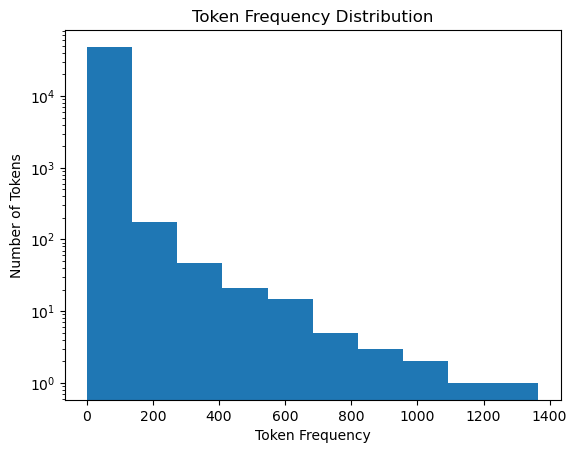

In [57]:
import pickle
from collections import Counter
import matplotlib.pyplot as plt

with open("data/all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

counts = []

for x in token_freq:
    counts.append(x[1])

plt.hist(counts)
plt.yscale("log")
plt.xlabel("Token Frequency")
plt.ylabel("Number of Tokens")
plt.title("Token Frequency Distribution")
plt.show()

In [61]:
## Most tokens appear only a small number of times, while a small number of tokens appear very frequently. The distribution is very right-skewed. Using the log scale makes it easier to see the differences between the less frequent tokens instead of having almost all of them crowded into one part of the graph.

In [63]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training R2:", model.score(X_train, y_train))
print("Testing R2:", model.score(X_test, y_test))

coef = pd.Series(model.coef_, index=X.columns)
top_words = coef.abs().sort_values(ascending=False).head(10)

print(top_words)

Training R2: 0.7670143724934355
Testing R2: 0.6658718438847929
intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
gray;                0.574480
dtype: float64


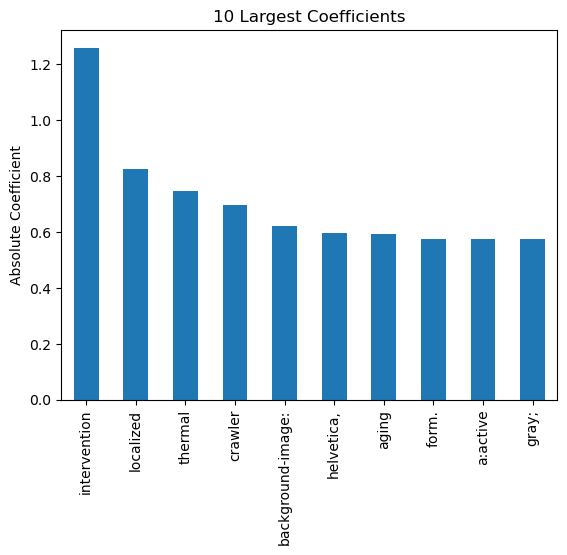

In [64]:
top_words.plot(kind="bar")
plt.ylabel("Absolute Coefficient")
plt.title("10 Largest Coefficients")
plt.show()

In [67]:
## The training R2 is about 0.77 and the testing R2 is about 0.67, so the model performs better on the training data. The coefficient graph makes it easier to see which tokens have the strongest effect on the predictions. Larger absolute coefficients mean that the variable has a stronger effect on the regression prediction.

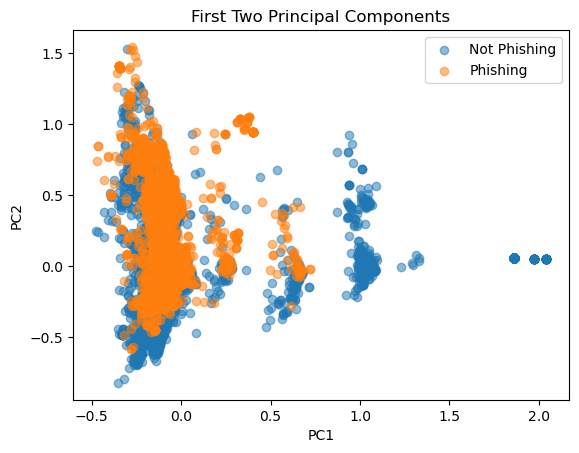

Explained variance: [0.0111309  0.00861137]


In [69]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    label="Not Phishing",
    alpha=.5
)

plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    label="Phishing",
    alpha=.5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("First Two Principal Components")
plt.legend()
plt.show()

print("Explained variance:", pca.explained_variance_ratio_)

In [71]:
## There is some separation between phishing and non-phishing emails, but there is still a lot of overlap. This shows that the first two principal components capture some differences between the groups but are not enough to completely separate them. The explained variance also shows how much of the variation in the original data is represented by these two components.

In [73]:
pca2 = PCA(n_components=2610)

X_train_pca = pca2.fit_transform(X_train)
X_test_pca = pca2.transform(X_test)

model2 = LinearRegression()
model2.fit(X_train_pca, y_train)

print("PCA Training R2:", model2.score(X_train_pca, y_train))
print("PCA Testing R2:", model2.score(X_test_pca, y_test))

print("Original Training R2:", model.score(X_train, y_train))
print("Original Testing R2:", model.score(X_test, y_test))

PCA Training R2: 0.7662326827745852
PCA Testing R2: 0.6683390643101161
Original Training R2: 0.7670143724934355
Original Testing R2: 0.6658718438847929


In [74]:
## The PCA regression and the original regression performed very similarly. The original model had a training R2 of about 0.77 and a testing R2 of about 0.67. The PCA model also had about 0.77 for training and 0.67 for testing, with the PCA model performing slightly better on the test data. This shows that PCA was able to reduce the dimensions somewhat without losing much predictive performance.

In [75]:
## PCA is useful in high-dimensional regression because it can take a large number of original variables and combine them into a smaller set of principal components. This can reduce repeated or highly related information between variables while still keeping much of the variation in the data. It can make the regression easier to work with and sometimes help it generalize better. One disadvantage is that the principal components are combinations of many original variables, so they are harder to interpret than individual words or tokens.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]